In [1]:
import os
import calendar
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# ============================================================
# Settings
# ============================================================
year = 2010
target_lon = 30.09
target_lat = 20.09

mask_file = "/work7/IPCS_extreme/share/thirstwave_detection/valid_event_days_1981_2023.nc"
p90_file  = "/work/home/H.extreme/IPCS_extreme/share/thirstwave_detection/tx01_90_c.nc"
era5_file = "/work5/ERA5_daily_landgrid_only/global/compressed_sfc_fc_daily_198001.nc4"
etos_dir  = "/work/home/H.extreme/IPCS_extreme/share/daily_ETos/ETos_term"

outfig = f"thirstwave_detection_{year}_{target_lon:.2f}E_{target_lat:.2f}N.png"

years = np.arange(1981, 2024)

# ============================================================
# Helper
# ============================================================
def remove_feb29_if_needed(data, year, month):
    if month == 2 and calendar.isleap(year):
        if data.shape[0] == 29:
            data = np.delete(data, 28, axis=0)
    return data

def growing_month_mask(lat, month):
    if lat >= 0:
        return 4 <= month <= 10
    else:
        return (month >= 10) or (month <= 4)

# ============================================================
# Read mask, threshold, and lat/lon
# ============================================================
ds_mask = xr.open_dataset(mask_file)
mask_all = ds_mask["ETos"].values.astype(bool)   # (time, lgrid)
lgrid = ds_mask["lgrid"].values

ds_p90 = xr.open_dataset(p90_file)
p90_all = ds_p90["ETos"].values                  # (365, lgrid)

ds_era5 = xr.open_dataset(era5_file)
lat_1d = ds_era5["lat"].values
lon_1d = ds_era5["lon"].values

lat_grid = lat_1d[lgrid]
lon_grid = lon_1d[lgrid]

# nearest landgrid
dist2 = (lat_grid - target_lat) ** 2 + (lon_grid - target_lon) ** 2
ig = int(np.argmin(dist2))

actual_lat = lat_grid[ig]
actual_lon = lon_grid[ig]

print(f"Nearest grid: {actual_lon:.2f}E, {actual_lat:.2f}N")

# ============================================================
# Find time index offset for selected year
# 365-day calendar after removing Feb 29
# ============================================================
year_index = np.where(years == year)[0][0]
t_start_year = year_index * 365

# ============================================================
# Read selected year ETos and construct growing-season series
# ============================================================
etos_list = []
p90_list = []
mask_list = []
time_list = []

t_index = t_start_year
doy_index = 0

for m in range(1, 13):
    etos_file = f"{etos_dir}/ETos_{year}{m:02d}.npy"
    if not os.path.exists(etos_file):
        raise FileNotFoundError(etos_file)

    data = np.load(etos_file).astype(np.float32)
    data = remove_feb29_if_needed(data, year, m)
    nday = data.shape[0]

    # daily values at selected grid
    etos_m = data[:, ig]
    p90_m = p90_all[doy_index:doy_index + nday, ig]
    mask_m = mask_all[t_index:t_index + nday, ig]

    # dates, excluding Feb 29 if needed
    dates = np.array(
        np.arange(
            np.datetime64(f"{year}-{m:02d}-01"),
            np.datetime64(f"{year}-{m:02d}-01") + np.timedelta64(nday, "D")
        ),
        dtype="datetime64[D]"
    )

    # growing season only
    if growing_month_mask(actual_lat, m):
        etos_list.append(etos_m)
        p90_list.append(p90_m)
        mask_list.append(mask_m)
        time_list.append(dates)

    t_index += nday
    doy_index += nday

etos_y = np.concatenate(etos_list)
p90_y = np.concatenate(p90_list)
mask_y = np.concatenate(mask_list)
time_y = np.concatenate(time_list)

# ============================================================
# Count events
# ============================================================
event_bool = mask_y.astype(int)

starts = np.where((event_bool[1:] == 1) & (event_bool[:-1] == 0))[0] + 1
if event_bool[0] == 1:
    starts = np.insert(starts, 0, 0)

n_events_year = len(starts)

# total events 1981–2023 at this grid
event_all = mask_all[:, ig].astype(int)
starts_all = np.where((event_all[1:] == 1) & (event_all[:-1] == 0))[0] + 1
if event_all[0] == 1:
    starts_all = np.insert(starts_all, 0, 0)

n_events_all = len(starts_all)


Nearest grid: 30.09E, 20.09N


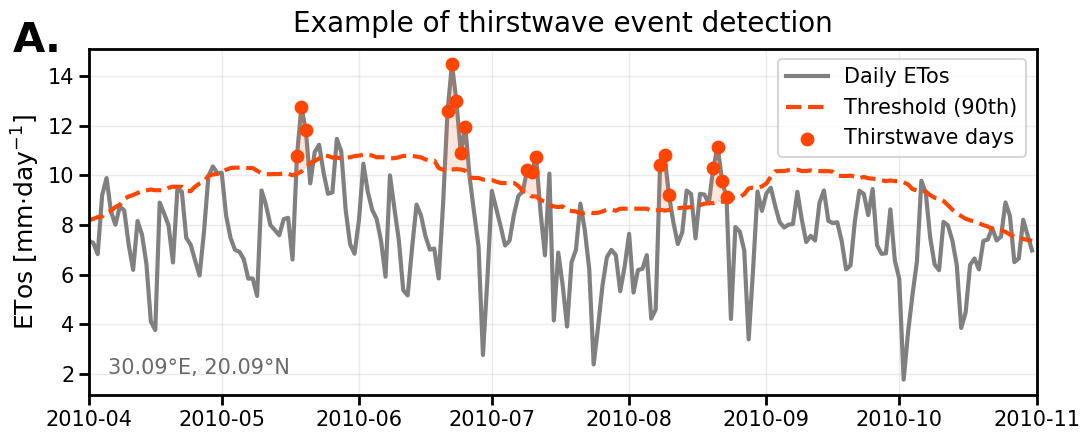

Saved: Figure/thirstwave_detection_exp.png


In [2]:
# ============================================================
# Plot
# ============================================================
outfig = f"Figure/thirstwave_detection_exp.png"

fig, ax = plt.subplots(figsize=(11, 4.5))

# thicker spines
for spine in ax.spines.values():
    spine.set_linewidth(2)

ax.plot(
    time_y, etos_y,
    color="gray", lw=3,
    label=r"Daily ETos"
)

ax.plot(
    time_y, p90_y,
    color="orangered", lw=3, ls="--",
    label="Threshold (90th)"
)

ax.scatter(
    time_y[mask_y], etos_y[mask_y],
    s=80,
    color="orangered",
    zorder=5,
    label="Thirstwave days"
)
# shaded thirstwave anomaly
ax.fill_between(
    time_y,
    p90_y,
    etos_y,
    where=mask_y & (etos_y > p90_y),
    color="#e9784a",
    alpha=0.18,
    interpolate=True,
    zorder=2
)
ax.set_title(
    rf"Example of thirstwave event detection",
    fontsize=20,
    pad=12
)

ax.set_ylabel(
    r"ETos [mm·day$^{-1}$]",
    fontsize=18
)


# larger ticks
ax.tick_params(
    axis='both',
    labelsize=15,
    width=2,
    length=7
)

# panel label
ax.text(
    -0.08, 1.08, "A.",
    transform=ax.transAxes,
    fontsize=30,
    fontweight="bold",
    va="top",
    ha="left"
)

# textbox
ax.text(
    0.02, 0.05,
    rf"{actual_lon:.2f}°E, {actual_lat:.2f}°N",
    transform=ax.transAxes,
    fontsize=15,
    color="dimgray",
    ha="left",
    va="bottom"
)
# legend
leg = ax.legend(
    loc="upper right",
    fontsize=15,
    frameon=True
)

leg.get_frame().set_linewidth(1.5)

# grid
ax.grid(
    True,
    alpha=0.25,
    linewidth=1
)

# ============================================================
# Identify thirstwave events from mask_y
# ============================================================
event_bool = mask_y.astype(bool)

starts = np.where(event_bool & ~np.r_[False, event_bool[:-1]])[0]
ends   = np.where(event_bool & ~np.r_[event_bool[1:], False])[0]

# event properties
event_lengths = ends - starts + 1

# choose one clear event for annotation: longest event
ievent = np.argmax(event_lengths)
i1 = starts[ievent]
i2 = ends[ievent]

event_mid = (i1 + i2) // 2
event_top = np.nanmax(etos_y[i1:i2+1])
event_thr = np.nanmean(p90_y[i1:i2+1])
event_intensity = np.nanmean(etos_y[i1:i2+1] - p90_y[i1:i2+1])


# remove x-axis padding
ax.set_xlim(
    np.datetime64(f"{year}-04-01"),
    np.datetime64(f"{year}-11-01")
)

fig.tight_layout()

fig.savefig(
    outfig,
    dpi=500,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {outfig}")

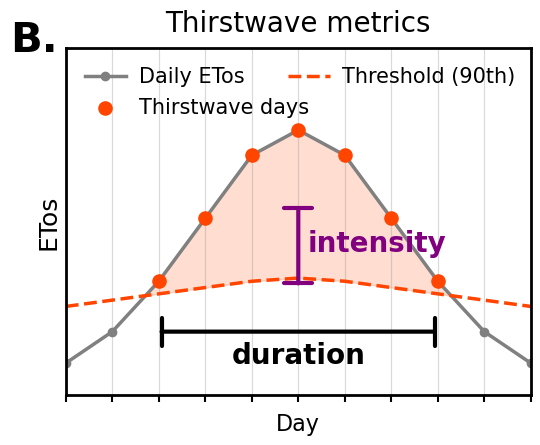

In [3]:
import numpy as np
import matplotlib.pyplot as plt
outfig = f"Figure/thirstwave_detection_sch.png"

# ============================================================
# Synthetic 10-day example
# ============================================================
days = np.arange(1, 12)

etos =      np.array([3.5, 4.0, 4.8, 5.8, 6.8, 7.2,  6.8, 5.8, 4.8, 4.0, 3.5])
threshold = np.array([4.4, 4.5, 4.6, 4.7, 4.8, 4.85, 4.8, 4.7, 4.6, 4.5, 4.4])

tw_mask = etos > threshold

starts = np.where(tw_mask & ~np.r_[False, tw_mask[:-1]])[0]
ends   = np.where(tw_mask & ~np.r_[tw_mask[1:], False])[0]

i1, i2 = starts[0], ends[0]
duration = i2 - i1 + 1

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(figsize=(6, 4.5))
for spine in ax.spines.values():
    spine.set_linewidth(2)
ax.plot(days, etos, color="gray", lw=2.5, marker="o", label="Daily ETos")
ax.scatter(days[tw_mask], etos[tw_mask], s=90, color="orangered", zorder=5, label="Thirstwave days")
ax.plot(days, threshold, color="orangered", lw=2.5, ls="--", label="Threshold (90th)")

ax.fill_between(
    days, threshold, etos,
    where=tw_mask,
    color="orangered",
    alpha=0.18,
    interpolate=True
)

# Duration bracket
y_bracket = 7.45

ax.annotate(
    "",
    xy=(days[i1], 4),
    xytext=(days[i2], 4),
    arrowprops=dict(arrowstyle="|-|", lw=3, color="black")
)

ax.text(
    (days[i1] + days[i2]) / 2,
    3.4,
    f"duration",
    ha="center",
    va="bottom",
    fontsize=20,
    color="k",
    fontweight="bold"
)

# Intensity arrow
x_int = 6
y_thr = np.interp(x_int, days, threshold)
y_etos = np.interp(x_int, days, etos)

ax.annotate(
    "",
    xy=(x_int, 6),
    xytext=(x_int, 4.7214),
    arrowprops=dict(arrowstyle="|-|", lw=3, color="purple")
)

ax.text(
    7.7,
    5.4,
    "intensity",
    ha="center",
    va="center",
    fontsize=20,
    color="purple",
    fontweight="bold"
)

ax.set_xlim(1, 11)
ax.set_ylim(3, 8.5)
ax.set_xticks([])
ax.set_yticks([])

ax.set_xticks(days)
ax.set_xticklabels([])

ax.tick_params(
    axis='x',
    which='major',
    bottom=True,
    top=False,
    length=5,      # 小延伸長度
    width=1.5,
    direction='out'
)

ax.set_xlabel("Day", fontsize=16)
ax.set_ylabel(r"ETos", fontsize=18)

ax.legend(
    loc="upper left",
    fontsize=15,
    frameon=False,
    ncol=2,
    columnspacing=-1,
    handletextpad=0.6
)
ax.grid(alpha=0.25)
ax.text(
    -0.12, 1.08, "B.",
    transform=ax.transAxes,
    fontsize=30,
    fontweight="bold",
    va="top",
    ha="left"
)

ax.set_title(
    rf"Thirstwave metrics",
    fontsize=20,
    pad=12
)
# vertical helper lines
for x in range(1, 12):
    ax.axvline(
        x,
        color="gray",
        lw=0.8,
        alpha=0.18,
        zorder=0
    )
fig.savefig(
    outfig,
    dpi=500,
    bbox_inches="tight"
)

plt.show()

✓ Figure/Figure1_upper.png
✓ Figure/Figure1_upper.pdf


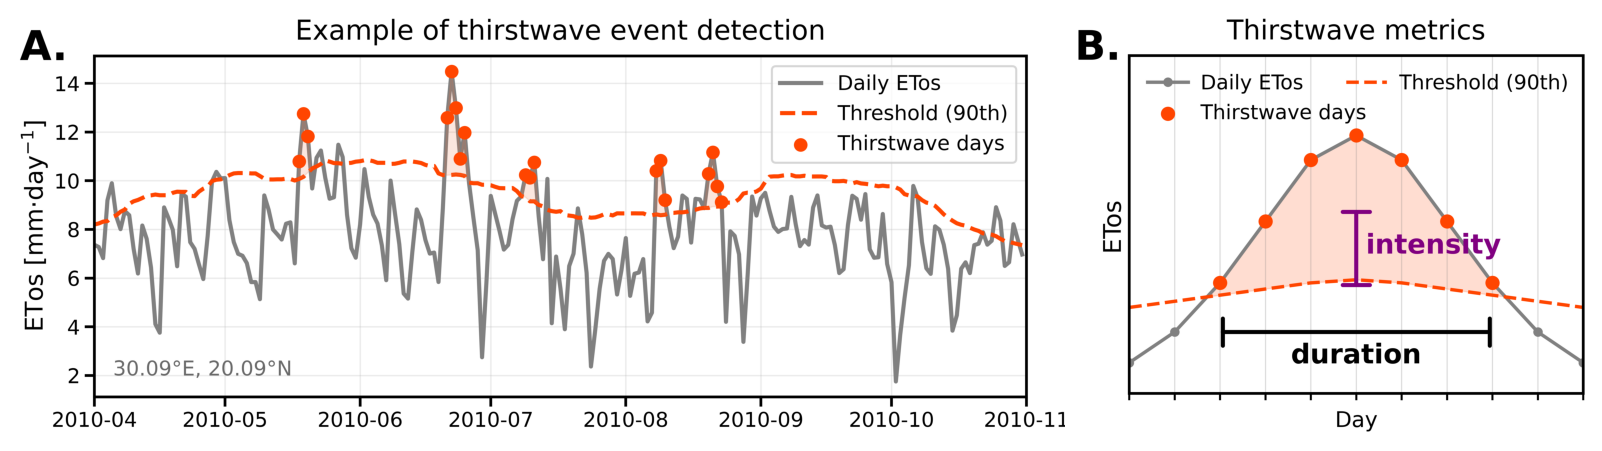

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img_left  = Image.open("Figure/thirstwave_detection_exp.png")
img_right = Image.open("Figure/thirstwave_detection_sch.png")

fig = plt.figure(figsize=(17, 4.5))

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[12, 6],
    wspace=-0.11
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

ax1.imshow(img_left)
ax2.imshow(img_right)

for ax in [ax1, ax2]:
    ax.axis("off")
    ax.set_anchor("C")

plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.02)

for ext in ["png", "pdf"]:
    filename = f"{ext}/Figure1_upper.{ext}"
    fig.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0.05)
    print(f"✓ {filename}")